<a id="1"></a>
# <div style="padding:20px;color:white;margin:0;font-size:28px;font-family:Georgia;text-align:center;display:fill;border-radius:5px;background-color:#0D647F;overflow:hidden"><b>🌟 IBM HR Analytics Employee Attrition & Performance 🌟</b></div>

<a id="1"></a>
# <div style="padding:20px;color:white;margin:0;font-size:22px;font-family:Verdana;text-align:center;display:fill;border-radius:5px;background-color:#0D647F;overflow:hidden"><b> 🎬 Introduction 🎬</b></div>
## 📌 Business Problem

Employee attrition is costly: hiring, training and lost productivity add up. HR wants to understand **which employees are leaving and why**, so that they can act before good people walk out.

**Objective:** Find out why employees are leaving the company and give HR some recommendations.

**Dataset:** IBM HR Analytics Employee Attrition dataset (1,470 employees, 35 columns)

**Libraries used:** pandas, numpy, matplotlib, seaborn

**Steps**
1. Data Profiling
2. Data Cleaning
3. Exploratory Data Analysis (Univariate, Bivariate, Multivariate)
4. Insights and Recommendations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

## 1. Data Profiling
Loading the data and checking its size, columns and data types.



In [2]:
df = pd.read_csv("data/IBM_HR_Attrition.xlsx")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,College,Life Sciences,1,1,Medium,Female,94,High,2,Sales Executive,Very High,Single,5993,19479,8,Y,Yes,11,Excellent,Low,80,0,8,0,Bad,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,Below College,Life Sciences,1,2,High,Male,61,Medium,2,Research Scientist,Medium,Married,5130,24907,1,Y,No,23,Outstanding,Very High,80,1,10,3,Better,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,College,Other,1,4,Very High,Male,92,Medium,1,Laboratory Technician,High,Single,2090,2396,6,Y,Yes,15,Excellent,Medium,80,0,7,3,Better,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,Master,Life Sciences,1,5,Very High,Female,56,High,1,Research Scientist,High,Married,2909,23159,1,Y,Yes,11,Excellent,High,80,0,8,3,Better,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,Below College,Medical,1,7,Low,Male,40,High,1,Laboratory Technician,Medium,Married,3468,16632,9,Y,No,12,Excellent,Very High,80,1,6,3,Better,2,2,2,2


In [3]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (1470, 35)
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   str  
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   str  
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   str  
 14  JobLevel              

In [4]:
df.describe()

,Age,DailyRate,DistanceFromHome,EmployeeCount,EmployeeNumber,HourlyRate,JobLevel,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,1.0,1024.865306,65.891156,2.063946,6502.931293,14313.103401,2.693197,15.209524,80.0,0.793878,11.279592,2.799320,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,0.0,602.024335,20.329428,1.106940,4707.956783,7117.786044,2.498009,3.659938,0.0,0.852077,7.780782,1.289271,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.0,1.000000,30.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,80.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,1.0,491.250000,48.000000,1.000000,2911.000000,8047.000000,1.000000,12.000000,80.0,0.000000,6.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,1.0,1020.500000,66.000000,2.000000,4919.000000,14235.500000,2.000000,14.000000,80.0,1.000000,10.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,1.0,1555.750000,83.750000,3.000000,8379.000000,20461.500000,4.000000,18.000000,80.0,1.000000,15.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,1.0,2068.000000,100.000000,5.000000,19999.000000,26999.000000,9.000000,25.000000,80.0,3.000000,40.000000,6.000000,40.000000,18.000000,15.000000,17.000000


**Observation:** The data has 1,470 rows and 35 columns. Some columns such as `Education`, `JobSatisfaction` and `WorkLifeBalance` are already in text form, so no numeric codes need to be replaced.

In [5]:
# Checking the unique values of the text columns
df["JobSatisfaction"].unique(), df["WorkLifeBalance"].unique(), df["Education"].unique()

(<StringArray>
['Very High', 'Medium', 'High', 'Low']
Length: 4, dtype: str, <StringArray>
['Bad', 'Better', 'Good', 'Best']
Length: 4, dtype: str, <StringArray>
['College', 'Below College', 'Master', 'Bachelor', 'Doctor']
Length: 5, dtype: str)

## 2. Data Cleaning
### 2.1 Duplicates and missing values

In [6]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Duplicate rows: 0
Missing values: 0


In [7]:
df = df.drop_duplicates()
df = df.dropna()

There are no duplicates and no missing values, so the data is already clean in this respect.

### 2.1 Replace numeric codes with text

In [14]:
maps = {
    "Education": {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"},
    "EnvironmentSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobInvolvement": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "JobSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "RelationshipSatisfaction": {1: "Low", 2: "Medium", 3: "High", 4: "Very High"},
    "PerformanceRating": {3: "Excellent", 4: "Outstanding"},
    "WorkLifeBalance": {1: "Bad", 2: "Good", 3: "Better", 4: "Best"},
}
for col in maps:
    if df[col].dtype != "object" and str(df[col].dtype) != "str":
        df[col] = df[col].map(maps[col])

df[list(maps.keys())].head()

,Education,EnvironmentSatisfaction,JobInvolvement,JobSatisfaction,RelationshipSatisfaction,PerformanceRating,WorkLifeBalance
0,College,Medium,High,Very High,Low,Excellent,Bad
1,Below College,High,Medium,Medium,Very High,Outstanding,Better
2,College,Very High,Medium,High,Medium,Excellent,Better
3,Master,Very High,High,High,High,Excellent,Better
4,Below College,Low,High,Medium,Very High,Excellent,Better


### 2.2 Spelling mistakes and extra spaces

In [8]:
# remove extra spaces from all text columns
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()

# make BusinessTravel easier to read
df["BusinessTravel"] = df["BusinessTravel"].str.replace("_", " ")
df["BusinessTravel"].unique()

<StringArray>
['Travel Rarely', 'Travel Frequently', 'Non-Travel']
Length: 3, dtype: str

### 2.3 Correct data types

In [9]:
# text columns are changed to category type
for col in text_cols:
    df[col] = df[col].astype("category")

df.dtypes.head(15)

Age                           int64
Attrition                  category
BusinessTravel             category
DailyRate                     int64
Department                 category
DistanceFromHome              int64
Education                  category
EducationField             category
EmployeeCount                 int64
EmployeeNumber                int64
EnvironmentSatisfaction    category
Gender                     category
HourlyRate                    int64
JobInvolvement             category
JobLevel                      int64
dtype: object

### 2.4 Remove columns that are not required
- `EmployeeCount`, `Over18`, `StandardHours`: same value for every employee
- `EmployeeNumber`: only an ID
- `DailyRate`, `HourlyRate`, `MonthlyRate`: not related to `MonthlyIncome`, so `MonthlyIncome` is used as the salary column

In [10]:
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber",
                      "DailyRate", "HourlyRate", "MonthlyRate"])
df.shape

(1470, 28)

### 2.5 Create new columns

In [11]:
# Age groups
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 60],
                        labels=["18-25", "26-35", "36-45", "46-55", "56-60"])

# Income groups (4 equal parts)
df["IncomeBand"] = pd.qcut(df["MonthlyIncome"], 4,
                           labels=["Low", "Lower-Mid", "Upper-Mid", "High"])

# Years at company groups
df["TenureGroup"] = pd.cut(df["YearsAtCompany"], bins=[-1, 1, 3, 5, 10, 50],
                           labels=["0-1 yr", "2-3 yrs", "4-5 yrs", "6-10 yrs", "10+ yrs"])

# 1 = employee left, 0 = employee stayed
df["AttritionFlag"] = np.where(df["Attrition"] == "Yes", 1, 0)

df[["Age", "AgeGroup", "MonthlyIncome", "IncomeBand", "YearsAtCompany", "TenureGroup", "AttritionFlag"]].head()

,Age,AgeGroup,MonthlyIncome,IncomeBand,YearsAtCompany,TenureGroup,AttritionFlag
0,41,36-45,5993,Upper-Mid,6,6-10 yrs,1
1,49,46-55,5130,Upper-Mid,10,6-10 yrs,0
2,37,36-45,2090,Low,0,0-1 yr,1
3,33,26-35,2909,Low,8,6-10 yrs,0
4,27,26-35,3468,Lower-Mid,2,2-3 yrs,0


In [12]:
# save the cleaned data
df.to_csv("data/IBM_attrition_cleaned.csv", index=False)
print("Overall attrition %:", round(df["AttritionFlag"].mean() * 100, 1))

Overall attrition %: 16.1


## 3. Exploratory Data Analysis
### 3.1 Univariate Analysis (one column)

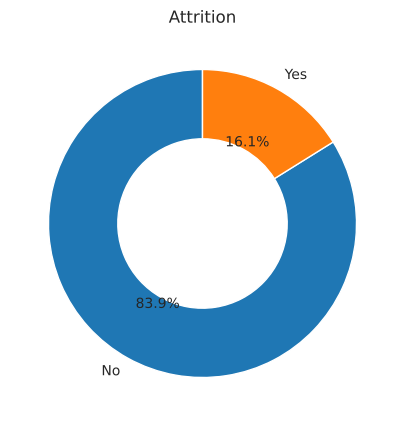

In [13]:
# Donut chart - how many employees left?
counts = df["Attrition"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
        wedgeprops=dict(width=0.45))
plt.title("Attrition")
plt.show()

**Insight:** About 16% of employees left and 84% stayed.

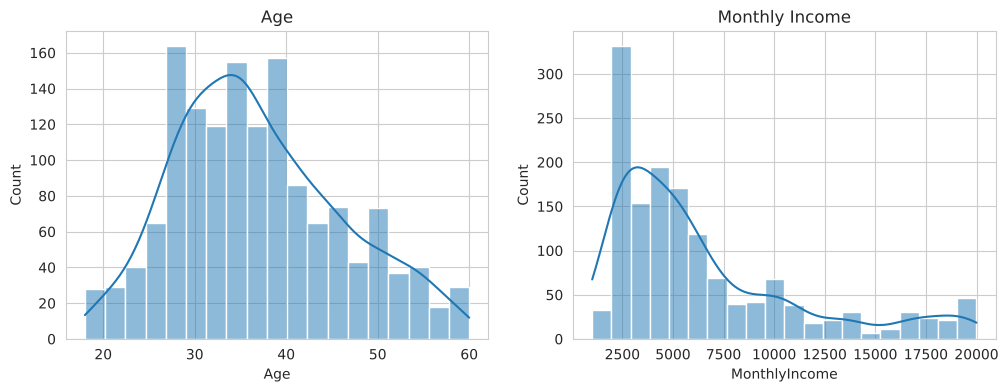

In [14]:
# Histogram with KDE - age and monthly income
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Age"], kde=True, ax=ax[0])
ax[0].set_title("Age")

sns.histplot(df["MonthlyIncome"], kde=True, ax=ax[1])
ax[1].set_title("Monthly Income")

plt.show()

**Insight:** The middle half of employees are between 30 and 43 years old (average age is about 37). Monthly income is right-skewed: most employees earn less, and a few earn a lot.

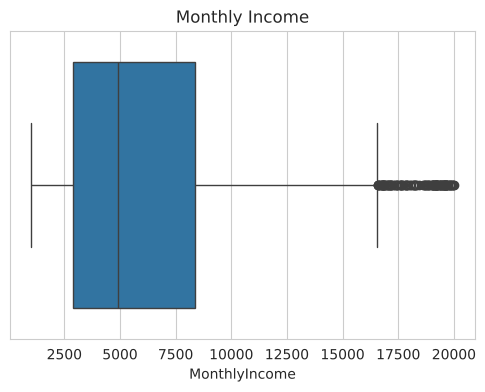

In [15]:
# Box plot - monthly income (to see outliers)
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["MonthlyIncome"])
plt.title("Monthly Income")
plt.show()

**Insight:** There are some high-income outliers. They are senior employees, not errors, so they are kept.

### 3.2 Bivariate Analysis (two columns)

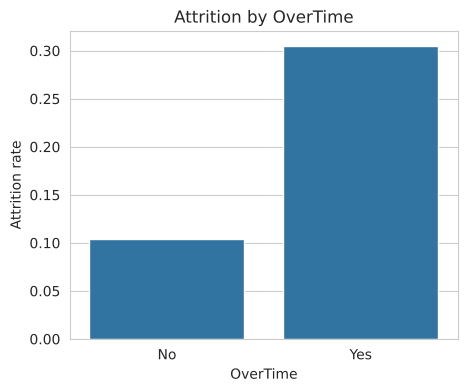

In [16]:
# Attrition % by OverTime
plt.figure(figsize=(5, 4))
sns.barplot(x="OverTime", y="AttritionFlag", data=df, ci=None)
plt.ylabel("Attrition rate")
plt.title("Attrition by OverTime")
plt.show()

**Insight:** Employees who work overtime leave much more (about 30%) than those who do not (about 10%).

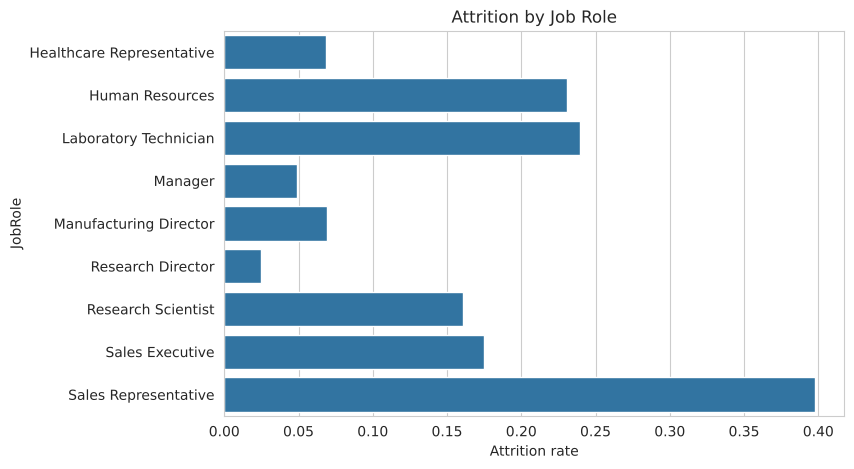

In [17]:
# Attrition % by Job Role
plt.figure(figsize=(8, 5))
sns.barplot(x="AttritionFlag", y="JobRole", data=df, ci=None)
plt.xlabel("Attrition rate")
plt.title("Attrition by Job Role")
plt.show()

**Insight:** Sales Representatives have the highest attrition (about 40%), followed by Laboratory Technicians and Human Resources.

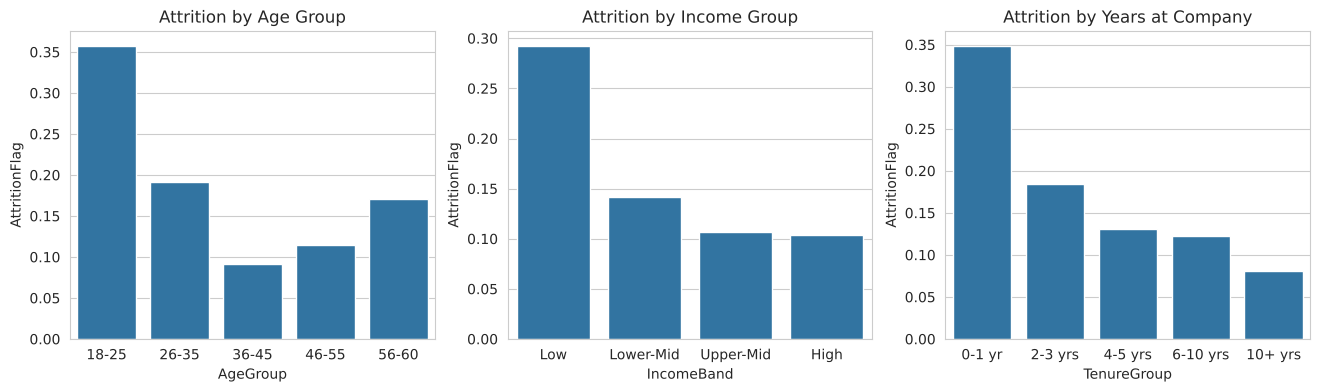

In [18]:
# Attrition % by Age group, Income group and Tenure group
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(x="AgeGroup", y="AttritionFlag", data=df, ci=None, ax=ax[0])
ax[0].set_title("Attrition by Age Group")

sns.barplot(x="IncomeBand", y="AttritionFlag", data=df, ci=None, ax=ax[1])
ax[1].set_title("Attrition by Income Group")

sns.barplot(x="TenureGroup", y="AttritionFlag", data=df, ci=None, ax=ax[2])
ax[2].set_title("Attrition by Years at Company")

plt.show()

**Insight:**
- Employees aged 18-25 leave the most (about 36%).
- The lowest income group has the highest attrition (about 29%).
- New employees in their first year leave the most (about 35%), and attrition falls as years at the company increase.

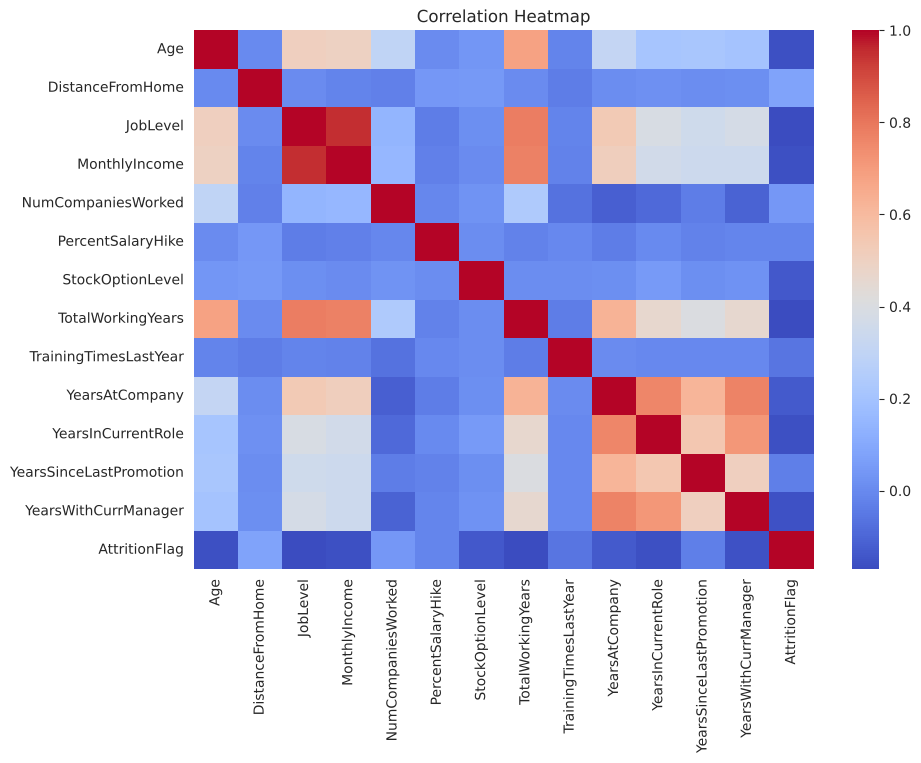

In [19]:
# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include="number").corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

**Insight:** `MonthlyIncome` is strongly related to `JobLevel` and `TotalWorkingYears`. The `Years...` columns are also related to each other.

### 3.3 Multivariate Analysis (more than two columns)

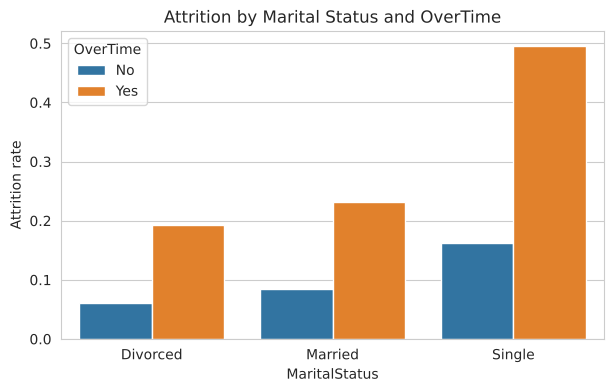

In [20]:
# OverTime and Marital Status together
plt.figure(figsize=(7, 4))
sns.barplot(x="MaritalStatus", y="AttritionFlag", hue="OverTime", data=df, ci=None)
plt.ylabel("Attrition rate")
plt.title("Attrition by Marital Status and OverTime")
plt.show()

**Insight:** Single employees who work overtime have the highest attrition (about 50%).

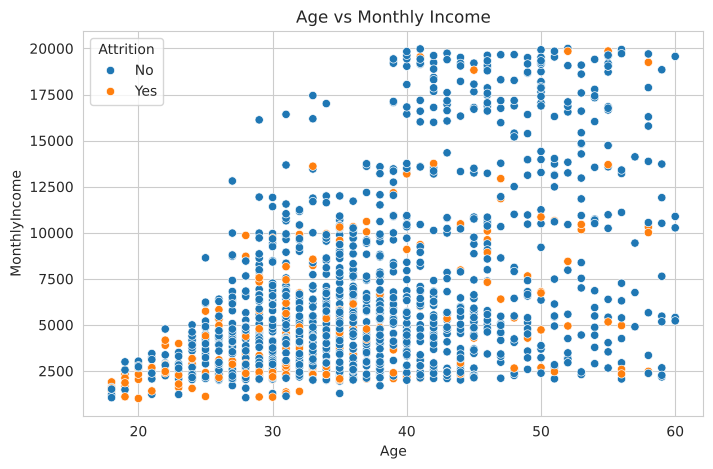

In [21]:
# Age, Income and Attrition together
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Age", y="MonthlyIncome", hue="Attrition", data=df)
plt.title("Age vs Monthly Income")
plt.show()

**Insight:** Employees who left are mostly young with low monthly income.


## 4. 🔍 Key Insights

|  | Finding | Evidence |
|---|---|---|
| 1 | **Overall attrition is 16.1%** | 237 of 1,470 employees left |
| 2 | **Overtime is the strongest driver** | 30.5% attrition with overtime vs 10.4% without |
| 3 | **Single + overtime is the riskiest group** | About 50% of them leave |
| 4 | **Sales Representatives leave the most** | About 40%, followed by Lab Technicians and HR (about 23-24%) |
| 5 | **Young and new employees are at risk** | Age 18-25 about 36%; first-year employees about 35% |
| 6 | **Low pay and no stock options push people out** | Lowest income band about 29%; no stock options about 24% |
| 7 | **Travel, commute and work-life balance matter** | Frequent travel about 25%; "Bad" work-life balance about 31%; 21-30 km commute about 22% |
| 8 | **Senior staff are stable** | Managers and Research Directors leave rarely (below 5%) |

> **Note:** these are patterns found in the data. They show association, not proof of cause.

---
## 5. ✅ Recommendations for HR

| Priority | Action | Why |
|---|---|---|
| 🔴 High | **Reduce and cap overtime**, especially in Sales, Lab and junior roles | Overtime triples the attrition rate |
| 🔴 High | **Improve the first-year experience** with onboarding, a mentor and check-ins at 3, 6 and 12 months | First-year attrition is the highest |
| 🟠 Medium | **Review pay** for the lowest income band and Sales Representatives; offer stock options to junior staff | Low pay and no stock options show high attrition |
| 🟠 Medium | **Build career paths for employees under 26** with clear promotion timelines | The youngest group leaves the most |
| 🟡 Low | **Limit frequent travel** and offer hybrid or remote options for long commutes | Travel and distance raise attrition |
| 🟡 Low | **Run regular satisfaction and work-life-balance surveys** and act on low scores | Early warning before people resign |


---
*Author: Neeraj Chauhan*